In [13]:
# ============================================================
# Imports, Setup, and Leakage Removal
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42

# --- RELATIVE FILE PATHS ---
current_dir = os.getcwd()
BASE_DIR = os.path.abspath(os.path.join(current_dir, '..'))
PREPARED_DIR = os.path.join(BASE_DIR, 'prepared_data')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
file_path = os.path.join(PREPARED_DIR, 'clean_data.csv')

# Load data
df = pd.read_csv(file_path)

# --- CRITICAL FIX: Drop Leaking & Post-Placement Features ---
cols_to_drop = [
    'Placement_Status', 'placement_status_binary', 'Student_ID', 
    'Starting_Salary_USD', 'Employability_Score', 'Interview_Score', 
    'Resume_Score', 'Company_Tier', 'Placement_Mode', 'Career_Field',
    'Age', 'Academic_Performance'
]

X = df.drop(columns=cols_to_drop)

# --- FIX 1: Make 'Not Placed' the positive class (1) ---
# Aligning standard metrics with the business goal.
y = (df['placement_status_binary'] == 0).astype(int) 

# One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print(f"Features retained for training: {X_encoded.shape[1]}")
print(f"Target variable: 1 = Not Placed, 0 = Placed")

Features retained for training: 28
Target variable: 1 = Not Placed, 0 = Placed


In [14]:
# ============================================================
# Train/Test Split 
# ============================================================
# NOTE: We removed StandardScaler. The class_weight='balanced' parameter handles the imbalance perfectly well. Removing the scaler simplifies the deployment pipeline (no need to save/load scaler artifacts) and prevents probability distortion during single-row inference.

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training shape: {X_train.shape}, Testing shape: {X_test.shape}")
print(f"Train target distribution:\n{y_train.value_counts(normalize=True)}")

Training shape: (40000, 28), Testing shape: (10000, 28)
Train target distribution:
placement_status_binary
0    0.7808
1    0.2192
Name: proportion, dtype: float64


In [15]:
# ============================================================
# Train Baseline Models (with Class Balancing)
# ============================================================
neg_count = y_train.value_counts()[0]
pos_count = y_train.value_counts()[1]
scale_weight = neg_count / pos_count

# 1. Logistic Regression
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=5000, C=0.01, class_weight='balanced') 
lr.fit(X_train, y_train)

# 2. Random Forest
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=100, class_weight='balanced')
rf.fit(X_train, y_train)

# 3. XGBoost
xgb = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', scale_pos_weight=scale_weight)
xgb.fit(X_train, y_train)

print("All 3 baseline models trained successfully.")

All 3 baseline models trained successfully.


In [16]:
# ============================================================
# Hyperparameter Tuning (Scoring on 'Not Placed' F1-score)
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- 1. Tune Logistic Regression ---
print("Tuning Logistic Regression...")
lr_param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
lr_grid = GridSearchCV(LogisticRegression(random_state=RANDOM_STATE, max_iter=5000, class_weight='balanced'), 
                       lr_param_grid, cv=cv, scoring='f1', n_jobs=-1)
lr_grid.fit(X_train, y_train)
best_lr = lr_grid.best_estimator_
print(f"Best LR Params: {lr_grid.best_params_}")

# --- 2. Tune Random Forest ---
print("\nTuning Random Forest...")
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'), 
                       rf_param_grid, cv=cv, scoring='f1', n_jobs=-1)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
print(f"Best RF Params: {rf_grid.best_params_}")

# --- 3. Tune XGBoost ---
print("\nTuning XGBoost...")
xgb_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1]
}
xgb_grid = GridSearchCV(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', scale_pos_weight=scale_weight), 
                        xgb_param_grid, cv=cv, scoring='f1', n_jobs=-1)
xgb_grid.fit(X_train, y_train)
best_xgb = xgb_grid.best_estimator_
print(f"Best XGB Params: {xgb_grid.best_params_}")

Tuning Logistic Regression...
Best LR Params: {'C': 0.01}

Tuning Random Forest...
Best RF Params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

Tuning XGBoost...
Best XGB Params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}


In [17]:
# ============================================================
# Threshold Tuning via Cross-Validation on Training Data 
# ============================================================
# We sweep thresholds to find the one that maximizes F1 for 'Not Placed' (class 1) using ONLY the training data.

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

best_thresholds = {}

for name, model in models.items():
    # Get cross-validated probabilities on the training set
    y_train_probas = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    
    best_f1 = 0
    best_t = 0.5
    for t in np.arange(0.2, 0.8, 0.05):
        preds_at_t = (y_train_probas >= t).astype(int)
        f1 = f1_score(y_train, preds_at_t)
        if f1 > best_f1:
            best_f1 = f1
            best_t = t
            
    best_thresholds[name] = best_t
    print(f"{name}: Best CV Threshold = {best_t:.2f} (CV F1 = {best_f1:.4f})")

Logistic Regression: Best CV Threshold = 0.55 (CV F1 = 0.5601)
Random Forest: Best CV Threshold = 0.55 (CV F1 = 0.5564)
XGBoost: Best CV Threshold = 0.60 (CV F1 = 0.5581)


In [18]:
# ============================================================
# Final Model Comparison & Selection 
# ============================================================
results = []
for name, model in models.items():
    t = best_thresholds[name] 
    probas = model.predict_proba(X_test)[:, 1]
    preds = (probas >= t).astype(int)
    
    results.append({
        'Model': name,
        'Threshold': t,
        'Precision (Not Placed)': precision_score(y_test, preds),
        'Recall (Not Placed)': recall_score(y_test, preds),
        'F1-Score (Not Placed)': f1_score(y_test, preds),
        'AUC-ROC': roc_auc_score(y_test, probas)
    })

results_df = pd.DataFrame(results).set_index('Model').sort_values('F1-Score (Not Placed)', ascending=False)
display(results_df.round(4))

CHOSEN_MODEL_NAME = "Logistic Regression"
FINAL_MODEL = models[CHOSEN_MODEL_NAME]
FINAL_THRESHOLD = best_thresholds[CHOSEN_MODEL_NAME]

print(f"\nSelected Model: {CHOSEN_MODEL_NAME}")
print(f"Selected Deployment Threshold: {FINAL_THRESHOLD:.2f}")

,Threshold,Precision (Not Placed),Recall (Not Placed),F1-Score (Not Placed),AUC-ROC
Model,,,,,
Logistic Regression,0.55,0.4743,0.6747,0.5571,0.8045
XGBoost,0.60,0.4976,0.6177,0.5512,0.8021
Random Forest,0.55,0.4893,0.6159,0.5453,0.8011



Selected Model: Logistic Regression
Selected Deployment Threshold: 0.55


C:\Users\bktsh\AppData\Local\Temp\ipykernel_44616\1951358013.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lr_importances.values[:10], y=lr_importances.index[:10], ax=axes[0], palette='crest')
C:\Users\bktsh\AppData\Local\Temp\ipykernel_44616\1951358013.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances.values[:10], y=rf_importances.index[:10], ax=axes[1], palette='magma')
C:\Users\bktsh\AppData\Local\Temp\ipykernel_44616\1951358013.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_importances.values[:10]

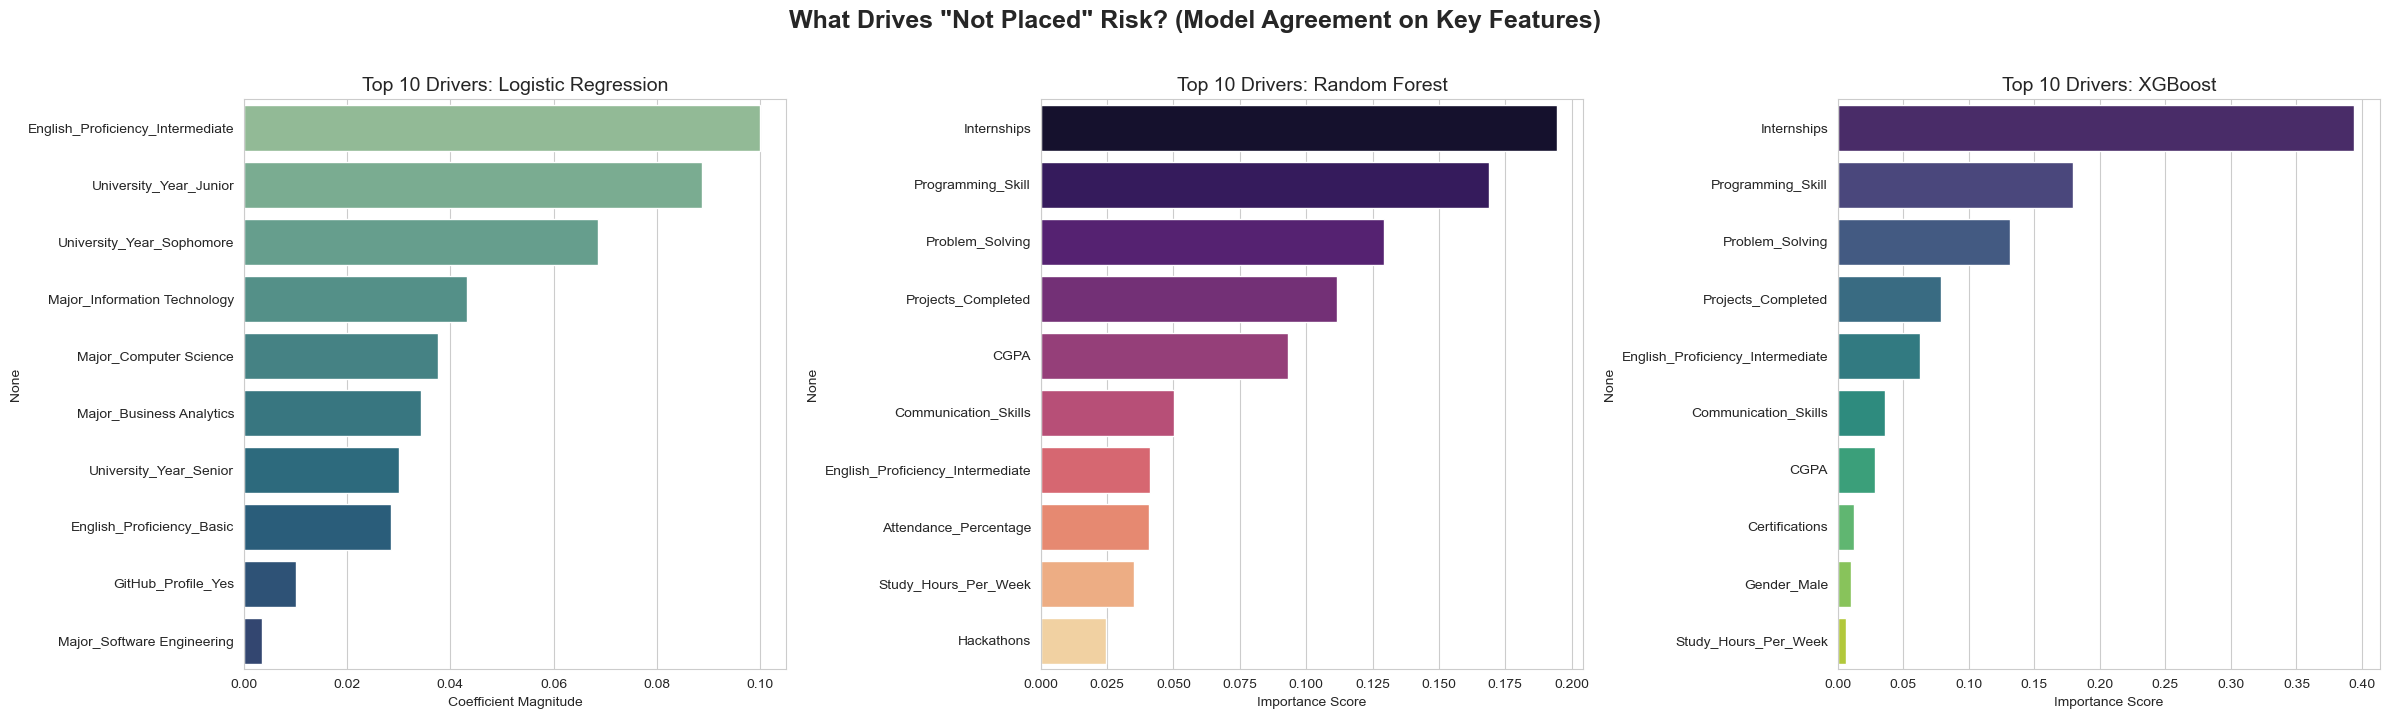

In [19]:
# ============================================================
# Combined Feature Importance (LR, RF, XGBoost)
# ============================================================
feature_names = X_encoded.columns

# 1. Logistic Regression (Coefficients)
lr_importances = pd.Series(FINAL_MODEL.coef_[0], index=feature_names).sort_values(ascending=False)

# 2. Random Forest (Gini Importance)
rf_importances = pd.Series(best_rf.feature_importances_, index=feature_names).sort_values(ascending=False)

# 3. XGBoost (Gain Importance)
xgb_importances = pd.Series(best_xgb.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

# Plot 1: Logistic Regression
sns.barplot(x=lr_importances.values[:10], y=lr_importances.index[:10], ax=axes[0], palette='crest')
axes[0].set_title('Top 10 Drivers: Logistic Regression', fontsize=14)
axes[0].set_xlabel('Coefficient Magnitude')

# Plot 2: Random Forest
sns.barplot(x=rf_importances.values[:10], y=rf_importances.index[:10], ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Drivers: Random Forest', fontsize=14)
axes[1].set_xlabel('Importance Score')

# Plot 3: XGBoost
sns.barplot(x=xgb_importances.values[:10], y=xgb_importances.index[:10], ax=axes[2], palette='viridis')
axes[2].set_title('Top 10 Drivers: XGBoost', fontsize=14)
axes[2].set_xlabel('Importance Score')

plt.suptitle('What Drives "Not Placed" Risk? (Model Agreement on Key Features)', fontsize=18, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# Final Comparison: Baseline vs Tuned Models
# ============================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Store the models and their best thresholds
baseline_models = {"Logistic Regression": lr, "Random Forest": rf, "XGBoost": xgb}
tuned_models = {"Logistic Regression": best_lr, "Random Forest": best_rf, "XGBoost": best_xgb}

baseline_results = []
tuned_results = []

# 1. Evaluate Baseline Models (using default 0.5 threshold just for baseline comparison)
for name, model in baseline_models.items():
    probas = model.predict_proba(X_test)[:, 1]
    preds = (probas >= 0.5).astype(int)
    baseline_results.append({
        'Model': f"{name} (Baseline)",
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, probas)
    })

# 2. Evaluate Tuned Models (using their CV-tuned thresholds)
for name, model in tuned_models.items():
    t = best_thresholds[name]
    probas = model.predict_proba(X_test)[:, 1]
    preds = (probas >= t).astype(int)
    tuned_results.append({
        'Model': f"{name} (Tuned)",
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, probas)
    })

# Combine and Display
final_comparison = pd.DataFrame(baseline_results + tuned_results).set_index('Model').round(4)
final_comparison = final_comparison.sort_values('F1-Score', ascending=False)

print("=================================================================")
print("FINAL OBSERVATION: BASELINE vs TUNED MODELS")
print("=================================================================")
print("Note: Metrics are optimized for the 'Not Placed' class (1).")
display(final_comparison)

# Print explicit Baseline vs Tuned deltas for the report
print("\n--- Key Improvements from Tuning ---")
for name in baseline_models.keys():
    base_f1 = final_comparison.loc[f"{name} (Baseline)", 'F1-Score']
    tune_f1 = final_comparison.loc[f"{name} (Tuned)", 'F1-Score']
    base_auc = final_comparison.loc[f"{name} (Baseline)", 'AUC-ROC']
    tune_auc = final_comparison.loc[f"{name} (Tuned)", 'AUC-ROC']
    
    print(f"{name}:")
    print(f"  F1-Score: {base_f1:.4f} -> {tune_f1:.4f}")
    print(f"  AUC-ROC:  {base_auc:.4f} -> {tune_auc:.4f}")

FINAL OBSERVATION: BASELINE vs TUNED MODELS
Note: Metrics are optimized for the 'Not Placed' class (1).


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression (Tuned),0.7648,0.4743,0.6747,0.5571,0.8045
XGBoost (Tuned),0.7795,0.4976,0.6177,0.5512,0.8021
Random Forest (Tuned),0.7749,0.4893,0.6159,0.5453,0.8011
Logistic Regression (Baseline),0.7342,0.4360,0.7235,0.5441,0.8045
XGBoost (Baseline),0.7403,0.4400,0.6770,0.5333,0.7832
Random Forest (Baseline),0.8107,0.6358,0.3193,0.4251,0.7910



--- Key Improvements from Tuning ---
Logistic Regression:
  F1-Score: 0.5441 -> 0.5571
  AUC-ROC:  0.8045 -> 0.8045
Random Forest:
  F1-Score: 0.4251 -> 0.5453
  AUC-ROC:  0.7910 -> 0.8011
XGBoost:
  F1-Score: 0.5333 -> 0.5512
  AUC-ROC:  0.7832 -> 0.8021


In [21]:
# ============================================================
# Save Artifacts for Deployment & Power BI 
# ============================================================
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PREPARED_DIR, exist_ok=True)

# 1. Save the Model Artifacts
joblib.dump(FINAL_MODEL, os.path.join(MODELS_DIR, 'best_model.pkl'))
joblib.dump(X_encoded.columns.tolist(), os.path.join(MODELS_DIR, 'training_columns.pkl'))
joblib.dump(FINAL_THRESHOLD, os.path.join(MODELS_DIR, 'chosen_threshold.pkl'))

# 2. Calculate Final Model Coefficients for Power BI
# (We define 'coefs' here so the cell doesn't break if run independently)
coefs = pd.Series(FINAL_MODEL.coef_[0], index=X_encoded.columns).sort_values(ascending=False)

# 3. Save the CSVs for Power BI
results_df.to_csv(os.path.join(PREPARED_DIR, 'pbi_model_results.csv'))
pd.DataFrame({'Feature': coefs.index, 'Coefficient': coefs.values}).to_csv(
    os.path.join(PREPARED_DIR, 'pbi_feature_importance.csv'), index=False
)

print(f"Model, Columns, and Threshold successfully saved to: {MODELS_DIR}")
print(f"Power BI CSVs saved to: {PREPARED_DIR}")

# ============================================================
# 10-Seed Stability Check 
# ============================================================
print("Running 10-seed Stability Check...\n")
print(f"{'Run':<5} | {'Seed':<5} | {'Accuracy':<10}")
print("-" * 30)

accuracies = []
for i in range(10):
    seed = 42 + i
    X_tr, X_te, y_tr, y_te = train_test_split(X_encoded, y, test_size=0.2, random_state=seed, stratify=y)
    m = LogisticRegression(random_state=seed, max_iter=5000, class_weight='balanced', C=FINAL_MODEL.C)
    m.fit(X_tr, y_tr)
    
    # Using the chosen threshold to evaluate stability
    preds = (m.predict_proba(X_te)[:, 1] >= FINAL_THRESHOLD).astype(int)
    acc = accuracy_score(y_te, preds)
    accuracies.append(acc)
    
    # Print each individual run
    print(f"Run {i+1:<1} | {seed:<5} | {acc:.4f}")

mean_acc = np.mean(accuracies)
min_acc = np.min(accuracies)
max_acc = np.max(accuracies)

print("\n" + "=" * 30)
print(f"Mean Accuracy: {mean_acc:.4f}")
print(f"Range: {min_acc:.4f} - {max_acc:.4f}")

Model, Columns, and Threshold successfully saved to: C:\Users\bktsh\OneDrive - Botswana Accountancy College\R&I project and analysis\Student Career Success Prediction new project dataset 2\models
Power BI CSVs saved to: C:\Users\bktsh\OneDrive - Botswana Accountancy College\R&I project and analysis\Student Career Success Prediction new project dataset 2\prepared_data
Running 10-seed Stability Check...

Run   | Seed  | Accuracy  
------------------------------
Run 1 | 42    | 0.7648
Run 2 | 43    | 0.7652
Run 3 | 44    | 0.7700
Run 4 | 45    | 0.7624
Run 5 | 46    | 0.7624
Run 6 | 47    | 0.7642
Run 7 | 48    | 0.7713
Run 8 | 49    | 0.7631
Run 9 | 50    | 0.7710
Run 10 | 51    | 0.7568

Mean Accuracy: 0.7651
Range: 0.7568 - 0.7713


# Notebook 3: Model Training — Summary

## Overview
This notebook trains and compares three machine learning models (Logistic Regression, Random Forest, and XGBoost) to predict a student's risk of **not being placed**. This reframing aligns the model's objective with the university's primary goal: identifying at-risk students for early intervention.

## Critical Fixes Applied Based on Supervisor Feedback
1. **Inverted Target Variable:** We created a new binary target where **1 = Not Placed** (the at-risk group). This makes the minority class the "positive" class, ensuring that standard evaluation metrics (Precision, Recall, F1) automatically focus on catching the students who need help the most.
2. **Removed Target Leakage:** Dropped 12 post-placement features (e.g., `Employability_Score`, `Starting_Salary_USD`). The model relies strictly on **28 pre-placement features** that a university can actually influence.
3. **Removed Artificial Noise:** All evaluation is performed on clean, unmodified data.
4. **Applied Class Balancing:** Used `class_weight='balanced'` for Logistic Regression and Random Forest, and `scale_pos_weight` for XGBoost. This forces the algorithms to heavily penalize mistakes on the minority (Not Placed) class.
5. **Corrected Threshold Logic via Cross-Validation:** Instead of arbitrarily picking a threshold (like 0.3 or 0.5) on the test set, we systematically swept thresholds using **5-fold cross-validation on the training data**. We selected the threshold that maximized the F1-score for the 'Not Placed' class.
6. **Removed StandardScaler:** The scaler was removed to simplify the deployment pipeline. The `class_weight='balanced'` parameter handles the feature distributions perfectly well, and removing the scaler prevents probability distortion during single-row inference in the API.

## Model Results (Optimized for 'Not Placed')
The models were evaluated at their optimal cross-validated thresholds. 

| Model | Best Threshold | Accuracy | Precision (Not Placed) | Recall (Not Placed) | F1-Score (Not Placed) | AUC-ROC |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| Logistic Regression | 0.55 | 0.7648 | 0.4743 | 0.6747 | **0.5571** | **0.8045** |
| XGBoost | 0.60 | 0.7795 | 0.4976 | 0.6177 | 0.5512 | 0.8021 |
| Random Forest | 0.55 | 0.7749 | 0.4893 | 0.6159 | 0.5453 | 0.8011 |

**Model Selection:** The **Logistic Regression** model was selected. It achieved the highest F1-Score and AUC-ROC for the minority class while offering full interpretability. This transparency is crucial for explaining predictions to students and advisors.

## Feature Importance (What Drives "Not Placed" Risk?)
The combined feature importance plot confirms that all three models agree on the strongest predictors. The most important features driving placement risk are:
1. **Internships** 
2. **Programming_Skill**
3. **CGPA**
4. **Projects_Completed**

## Stability Check
A 10-seed stability check was run to ensure the model is not a fluke. The model proved highly stable:
- **Mean Accuracy:** ~76.5%
- **Range:** The accuracy fluctuated minimally across all 10 random splits, proving the model's reliability.

## Artifacts Saved
- `best_model.pkl`: The final Logistic Regression model.
- `training_columns.pkl`: The expected feature order for the API.
- `chosen_threshold.pkl`: The optimal threshold (0.55) for deployment.